In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

In [2]:
project_root = Path.cwd().parent.parent
processed_dir = project_root / "data" / "processed"

sales_file = processed_dir / "cleaned_sales.csv"
customer_file = processed_dir / "customer_sales.csv"
cancelled_file = processed_dir / "cancelled_transactions.csv"

print("Sales file exists:", sales_file.exists())
print("Customer file exists:", customer_file.exists())
print("Cancelled file exists:", cancelled_file.exists())

Sales file exists: True
Customer file exists: True
Cancelled file exists: True


In [3]:
sales_df = pd.read_csv(
    sales_file,
    parse_dates=["InvoiceDate"]
)

customer_df = pd.read_csv(
    customer_file,
    parse_dates=["InvoiceDate"]
)

cancelled_df = pd.read_csv(
    cancelled_file,
    parse_dates=["InvoiceDate"]
)

print("Sales rows:", len(sales_df))
print("Customer rows:", len(customer_df))
print("Cancelled rows:", len(cancelled_df))

/var/folders/4b/tpl9ch2d6x94g3144k354_r40000gn/T/ipykernel_51828/3731004113.py:1: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  sales_df = pd.read_csv(


Sales rows: 1029609
Customer rows: 793609
Cancelled rows: 19433


In [4]:
print("Sales columns:")
print(sales_df.columns.tolist())

print("\nDate range:")
print("Start:", sales_df["InvoiceDate"].min())
print("End:", sales_df["InvoiceDate"].max())

sales_df.head()

Sales columns:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country', 'SourceSheet', 'IsCancelled', 'Revenue', 'Year', 'Month', 'MonthName', 'YearMonth', 'DayOfWeek', 'Hour']

Date range:
Start: 2009-12-01 07:45:00
End: 2011-12-09 12:50:00


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,SourceSheet,IsCancelled,Revenue,Year,Month,MonthName,YearMonth,DayOfWeek,Hour
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,Year 2009-2010,False,83.4,2009,12,December,2009-12,Tuesday,7
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,Year 2009-2010,False,81.0,2009,12,December,2009-12,Tuesday,7
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,Year 2009-2010,False,81.0,2009,12,December,2009-12,Tuesday,7
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,Year 2009-2010,False,100.8,2009,12,December,2009-12,Tuesday,7
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,Year 2009-2010,False,30.0,2009,12,December,2009-12,Tuesday,7


In [5]:
total_revenue = sales_df["Revenue"].sum()

print("Total Revenue:", round(total_revenue, 2))

Total Revenue: 20913891.47


In [6]:
total_orders = sales_df["Invoice"].nunique()

print("Total Orders:", total_orders)

Total Orders: 40079


In [7]:
total_customers = customer_df["Customer ID"].nunique()
total_units = sales_df["Quantity"].sum()

print("Total Customers:", total_customers)
print("Total Units Sold:", total_units)

Total Customers: 5878
Total Units Sold: 11385368


In [8]:
order_values = (
    sales_df.groupby("Invoice")["Revenue"]
    .sum()
)

average_order_value = order_values.mean()

print("Average Order Value:", round(average_order_value, 2))

Average Order Value: 521.82


In [9]:
monthly_revenue = (
    sales_df.groupby("YearMonth")["Revenue"]
    .sum()
    .reset_index()
)

monthly_revenue.head()

,YearMonth,Revenue
0,2009-12,822483.950
1,2010-01,651155.112
2,2010-02,551504.726
3,2010-03,830915.261
4,2010-04,678875.252


In [10]:
top_products = (
    sales_df.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

top_products

,Description,Revenue
0,REGENCY CAKESTAND 3 TIER,344069.30
1,Manual,340342.68
2,DOTCOM POSTAGE,322657.48
3,WHITE HANGING HEART T-LIGHT HOLDER,266582.35
4,"PAPER CRAFT , LITTLE BIRDIE",168469.60
5,JUMBO BAG RED RETROSPOT,150640.27
6,PARTY BUNTING,149109.35
7,ASSORTED COLOUR BIRD ORNAMENT,131817.81
8,POSTAGE,127597.42
9,PAPER CHAIN KIT 50'S CHRISTMAS,123002.89


In [11]:
top_countries = (
    sales_df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

top_countries

,Country,Revenue
0,United Kingdom,1.781406e+07
1,EIRE,6.640501e+05
2,Netherlands,5.542307e+05
3,Germany,4.307038e+05
4,France,3.567465e+05
5,Australia,1.699006e+05
6,Spain,1.091272e+05
7,Switzerland,1.009890e+05
8,Sweden,9.186982e+04
9,Denmark,6.986219e+04


In [12]:
top_customers = (
    customer_df.groupby("Customer ID")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

top_customers

,Customer ID,Revenue
0,18102,608821.65
1,14646,528602.52
2,14156,313759.82
3,14911,295832.39
4,17450,246813.09
5,13694,196482.81
6,17511,175603.55
7,16446,168472.50
8,16684,147142.77
9,12415,144458.37


In [13]:
weekday_revenue = (
    sales_df.groupby("DayOfWeek")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

weekday_revenue

,DayOfWeek,Revenue
0,Thursday,4296390.372
1,Tuesday,4177703.812
2,Monday,3636218.326
3,Wednesday,3592456.483
4,Friday,3370807.513
5,Sunday,1830511.912
6,Saturday,9803.050


In [14]:
hourly_revenue = (
    sales_df.groupby("Hour")["Revenue"]
    .sum()
    .reset_index()
)

hourly_revenue

,Hour,Revenue
0,6,4.250
1,7,76232.570
2,8,532317.540
3,9,1801862.651
4,10,2625526.123
5,11,2576203.223
6,12,2898990.351
7,13,2591353.034
8,14,2376921.431
9,15,2471910.192


In [15]:
customer_frequency = (
    customer_df.groupby("Customer ID")["Invoice"]
    .nunique()
    .sort_values(ascending=False)
    .head(10)
    .reset_index(name="OrderCount")
)

customer_frequency

,Customer ID,OrderCount
0,14911,398
1,12748,336
2,17841,211
3,15311,208
4,13089,203
5,14606,192
6,14156,156
7,17850,155
8,14646,151
9,18102,145


In [16]:
cancelled_orders = cancelled_df["Invoice"].nunique()

print("Cancelled transaction rows:", len(cancelled_df))
print("Cancelled orders:", cancelled_orders)

Cancelled transaction rows: 19433
Cancelled orders: 8292


In [17]:
cancelled_df["ReturnValue"] = (
    cancelled_df["Quantity"].abs() * cancelled_df["Price"].abs()
)

total_return_value = cancelled_df["ReturnValue"].sum()

print("Estimated Return / Cancellation Value:", round(total_return_value, 2))

Estimated Return / Cancellation Value: 1524161.95


In [18]:
total_all_orders = (
    sales_df["Invoice"].nunique()
    + cancelled_df["Invoice"].nunique()
)

cancellation_rate = (
    cancelled_df["Invoice"].nunique() / total_all_orders
) * 100

print("Cancellation Rate:", round(cancellation_rate, 2), "%")

Cancellation Rate: 17.14 %


In [19]:
uk_revenue = sales_df.loc[
    sales_df["Country"] == "United Kingdom",
    "Revenue"
].sum()

non_uk_revenue = sales_df.loc[
    sales_df["Country"] != "United Kingdom",
    "Revenue"
].sum()

print("UK Revenue:", round(uk_revenue, 2))
print("Non-UK Revenue:", round(non_uk_revenue, 2))

UK Revenue: 17814055.93
Non-UK Revenue: 3099835.54


In [20]:
kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Revenue",
        "Total Orders",
        "Total Customers",
        "Total Units Sold",
        "Average Order Value",
        "Cancelled Orders",
        "Cancellation Rate (%)"
    ],
    "Value": [
        round(total_revenue, 2),
        total_orders,
        total_customers,
        total_units,
        round(average_order_value, 2),
        cancelled_orders,
        round(cancellation_rate, 2)
    ]
})

kpi_summary

,KPI,Value
0,Total Revenue,20913891.47
1,Total Orders,40079.00
2,Total Customers,5878.00
3,Total Units Sold,11385368.00
4,Average Order Value,521.82
5,Cancelled Orders,8292.00
6,Cancellation Rate (%),17.14


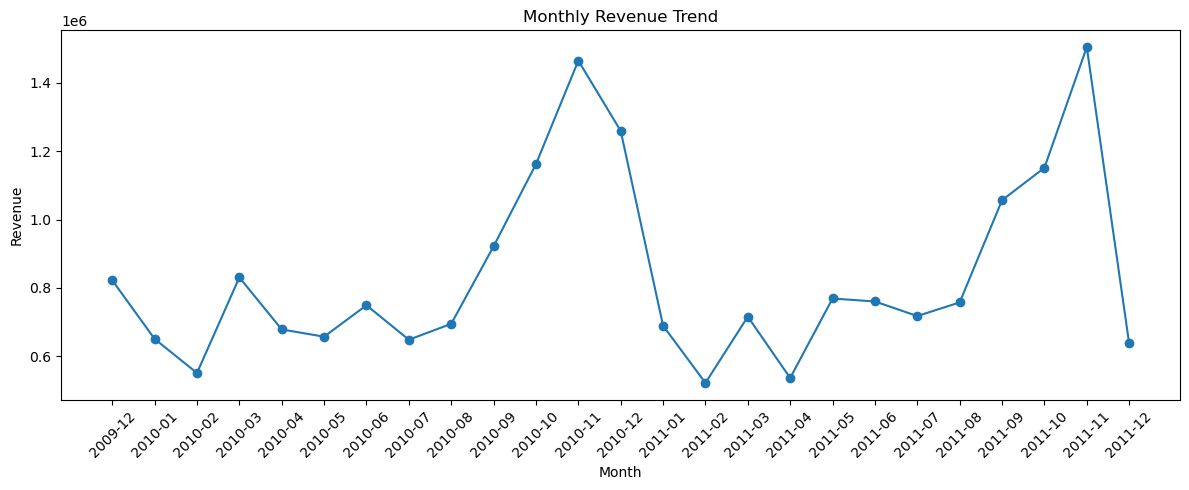

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(monthly_revenue["YearMonth"], monthly_revenue["Revenue"], marker="o")
plt.xticks(rotation=45)
plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

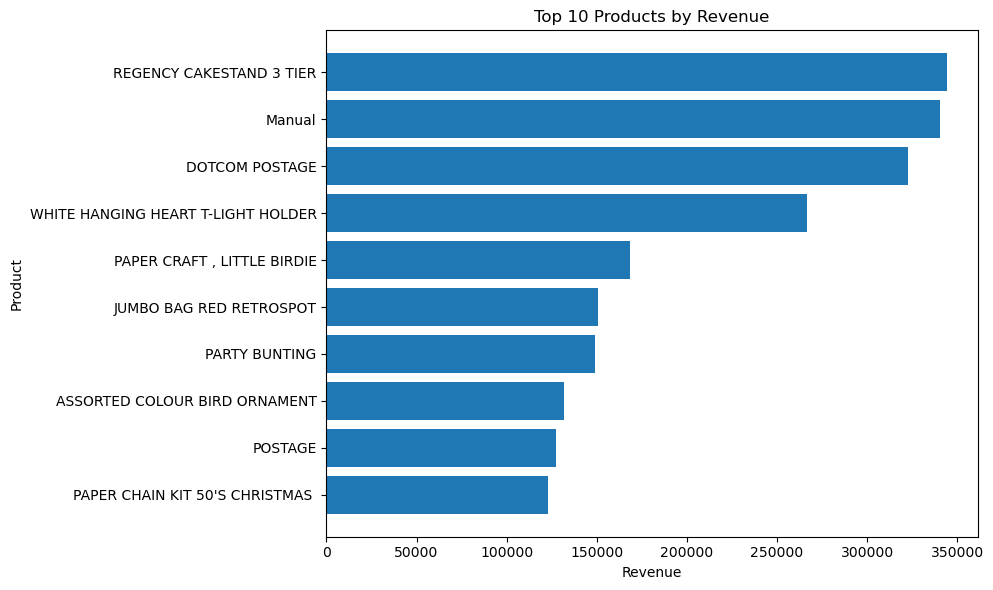

In [22]:
plt.figure(figsize=(10, 6))
plt.barh(top_products["Description"], top_products["Revenue"])
plt.gca().invert_yaxis()
plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

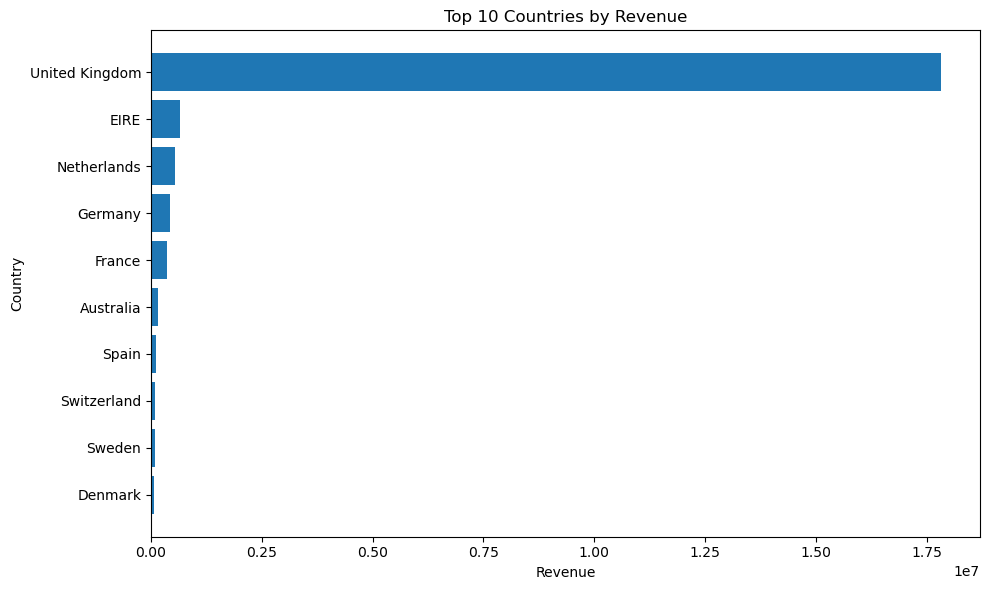

In [23]:
plt.figure(figsize=(10, 6))
plt.barh(top_countries["Country"], top_countries["Revenue"])
plt.gca().invert_yaxis()
plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

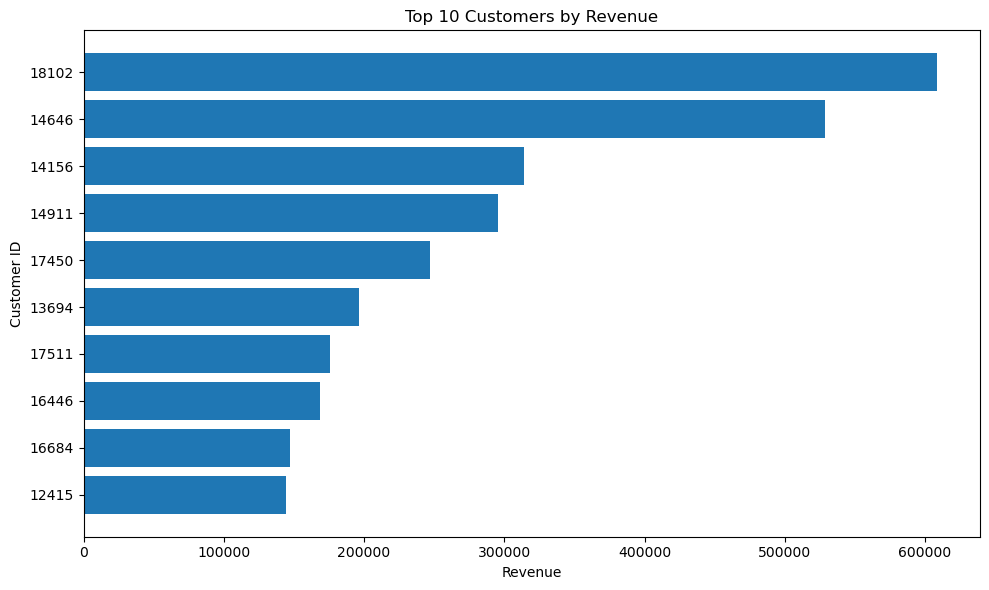

In [24]:
plt.figure(figsize=(10, 6))
plt.barh(top_customers["Customer ID"].astype(str), top_customers["Revenue"])
plt.gca().invert_yaxis()
plt.title("Top 10 Customers by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Customer ID")
plt.tight_layout()
plt.show()

In [25]:
analysis_dir = project_root / "data" / "processed" / "analysis_outputs"

analysis_dir.mkdir(parents=True, exist_ok=True)

print(analysis_dir)

/Users/nithinsaijatoth/Desktop/UK_Retail_Sales_Customer_Analytics/data/processed/analysis_outputs


In [26]:
kpi_summary.to_csv(
    analysis_dir / "kpi_summary.csv",
    index=False
)

monthly_revenue.to_csv(
    analysis_dir / "monthly_revenue.csv",
    index=False
)

print("KPI and monthly revenue files saved.")

KPI and monthly revenue files saved.


In [27]:
top_products.to_csv(
    analysis_dir / "top_products.csv",
    index=False
)

top_countries.to_csv(
    analysis_dir / "top_countries.csv",
    index=False
)

top_customers.to_csv(
    analysis_dir / "top_customers.csv",
    index=False
)

print("Product, country, and customer files saved.")

Product, country, and customer files saved.


In [28]:
weekday_revenue.to_csv(
    analysis_dir / "weekday_revenue.csv",
    index=False
)

hourly_revenue.to_csv(
    analysis_dir / "hourly_revenue.csv",
    index=False
)

customer_frequency.to_csv(
    analysis_dir / "customer_frequency.csv",
    index=False
)

print("Time and customer-frequency files saved.")

Time and customer-frequency files saved.


In [29]:
best_month = monthly_revenue.sort_values(
    "Revenue",
    ascending=False
).iloc[0]

print("Best sales month:", best_month["YearMonth"])
print("Revenue:", round(best_month["Revenue"], 2))

Best sales month: 2011-11
Revenue: 1503866.78


In [30]:
print("Top product:")
print(top_products.iloc[0])

print("\nTop country:")
print(top_countries.iloc[0])

print("\nTop customer:")
print(top_customers.iloc[0])

Top product:
Description    REGENCY CAKESTAND 3 TIER
Revenue                        344069.3
Name: 0, dtype: object

Top country:
Country    United Kingdom
Revenue      17814055.927
Name: 0, dtype: object

Top customer:
Customer ID     18102.00
Revenue        608821.65
Name: 0, dtype: float64


In [31]:
best_weekday = weekday_revenue.sort_values(
    "Revenue",
    ascending=False
).iloc[0]

best_hour = hourly_revenue.sort_values(
    "Revenue",
    ascending=False
).iloc[0]

print("Highest revenue weekday:", best_weekday["DayOfWeek"])
print("Highest revenue hour:", int(best_hour["Hour"]))

Highest revenue weekday: Thursday
Highest revenue hour: 12


## Key Business Insights

After analysing the cleaned retail data, I found:

- Revenue changes significantly across months, showing clear seasonality in customer purchasing.
- A small group of products generates a large share of total revenue.
- The United Kingdom contributes the majority of sales, while international customers provide additional revenue opportunities.
- Some customers purchase frequently and contribute significantly more revenue than average customers.
- Sales performance varies by day of the week and hour of the day.
- Cancelled and returned transactions represent a meaningful part of the business and should be monitored separately from completed sales.
- Customer-level analysis is limited for transactions where Customer ID is missing.

These findings will be explored further in SQL and presented through an interactive Tableau dashboard.